In [1]:
# CELL 0: Cấu hình xử lý video (chạy đầu tiên sau cài thư viện/import)
# CẤU HÌNH VIDEO CAMERA 30–45 FPS
FPS_MUC_TIEU = 15         # mục tiêu lượt phát hiện/giây video
CONF_XE = 0.25
CONF_BIEN_SO = 0.25
NGUONG_OCR = 0.80
OCR_TOI_DA_MOI_XE = 5    # tối đa 5 lượt OCR cho mỗi track biển số
IOU_GHEP_BIEN_SO = 0.25
THOI_GIAN_GIU_TRACK = 1.0  # giây video; mất track thì xóa

def tinh_buoc(fps):
    return max(1, round(fps / FPS_MUC_TIEU))

def lay_boxes(kq):
    return [(tuple(map(int,b.xyxy[0].tolist())), int(b.cls.item()),float(b.conf.item())) for b in kq.boxes]

def ve_boxes(frame, boxes, names=None, mau=(0,255,0), nhan_mac_dinh='bien so'):
    for (x1,y1,x2,y2),cls,conf in boxes:
        ten = names.get(cls, nhan_mac_dinh) if names is not None else nhan_mac_dinh
        cv2.rectangle(frame,(x1,y1),(x2,y2),mau,2)
        cv2.putText(frame,f'{ten} {conf:.2f}',(x1,max(20,y1-7)),cv2.FONT_HERSHEY_SIMPLEX,0.6,mau,2)

def iou_box(a,b):
    ax1,ay1,ax2,ay2=a;bx1,by1,bx2,by2=b
    inter=max(0,min(ax2,bx2)-max(ax1,bx1))*max(0,min(ay2,by2)-max(ay1,by1))
    union=max(1,(ax2-ax1)*(ay2-ay1)+(bx2-bx1)*(by2-by1)-inter)
    return inter/union


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Saving 1793006453713_187736382022377509_4522112729052546942_2542069a6074bf679d784b9c841bb445.jpg to 1793006453713_187736382022377509_4522112729052546942_2542069a6074bf679d784b9c841bb445.jpg
Số xe: 1


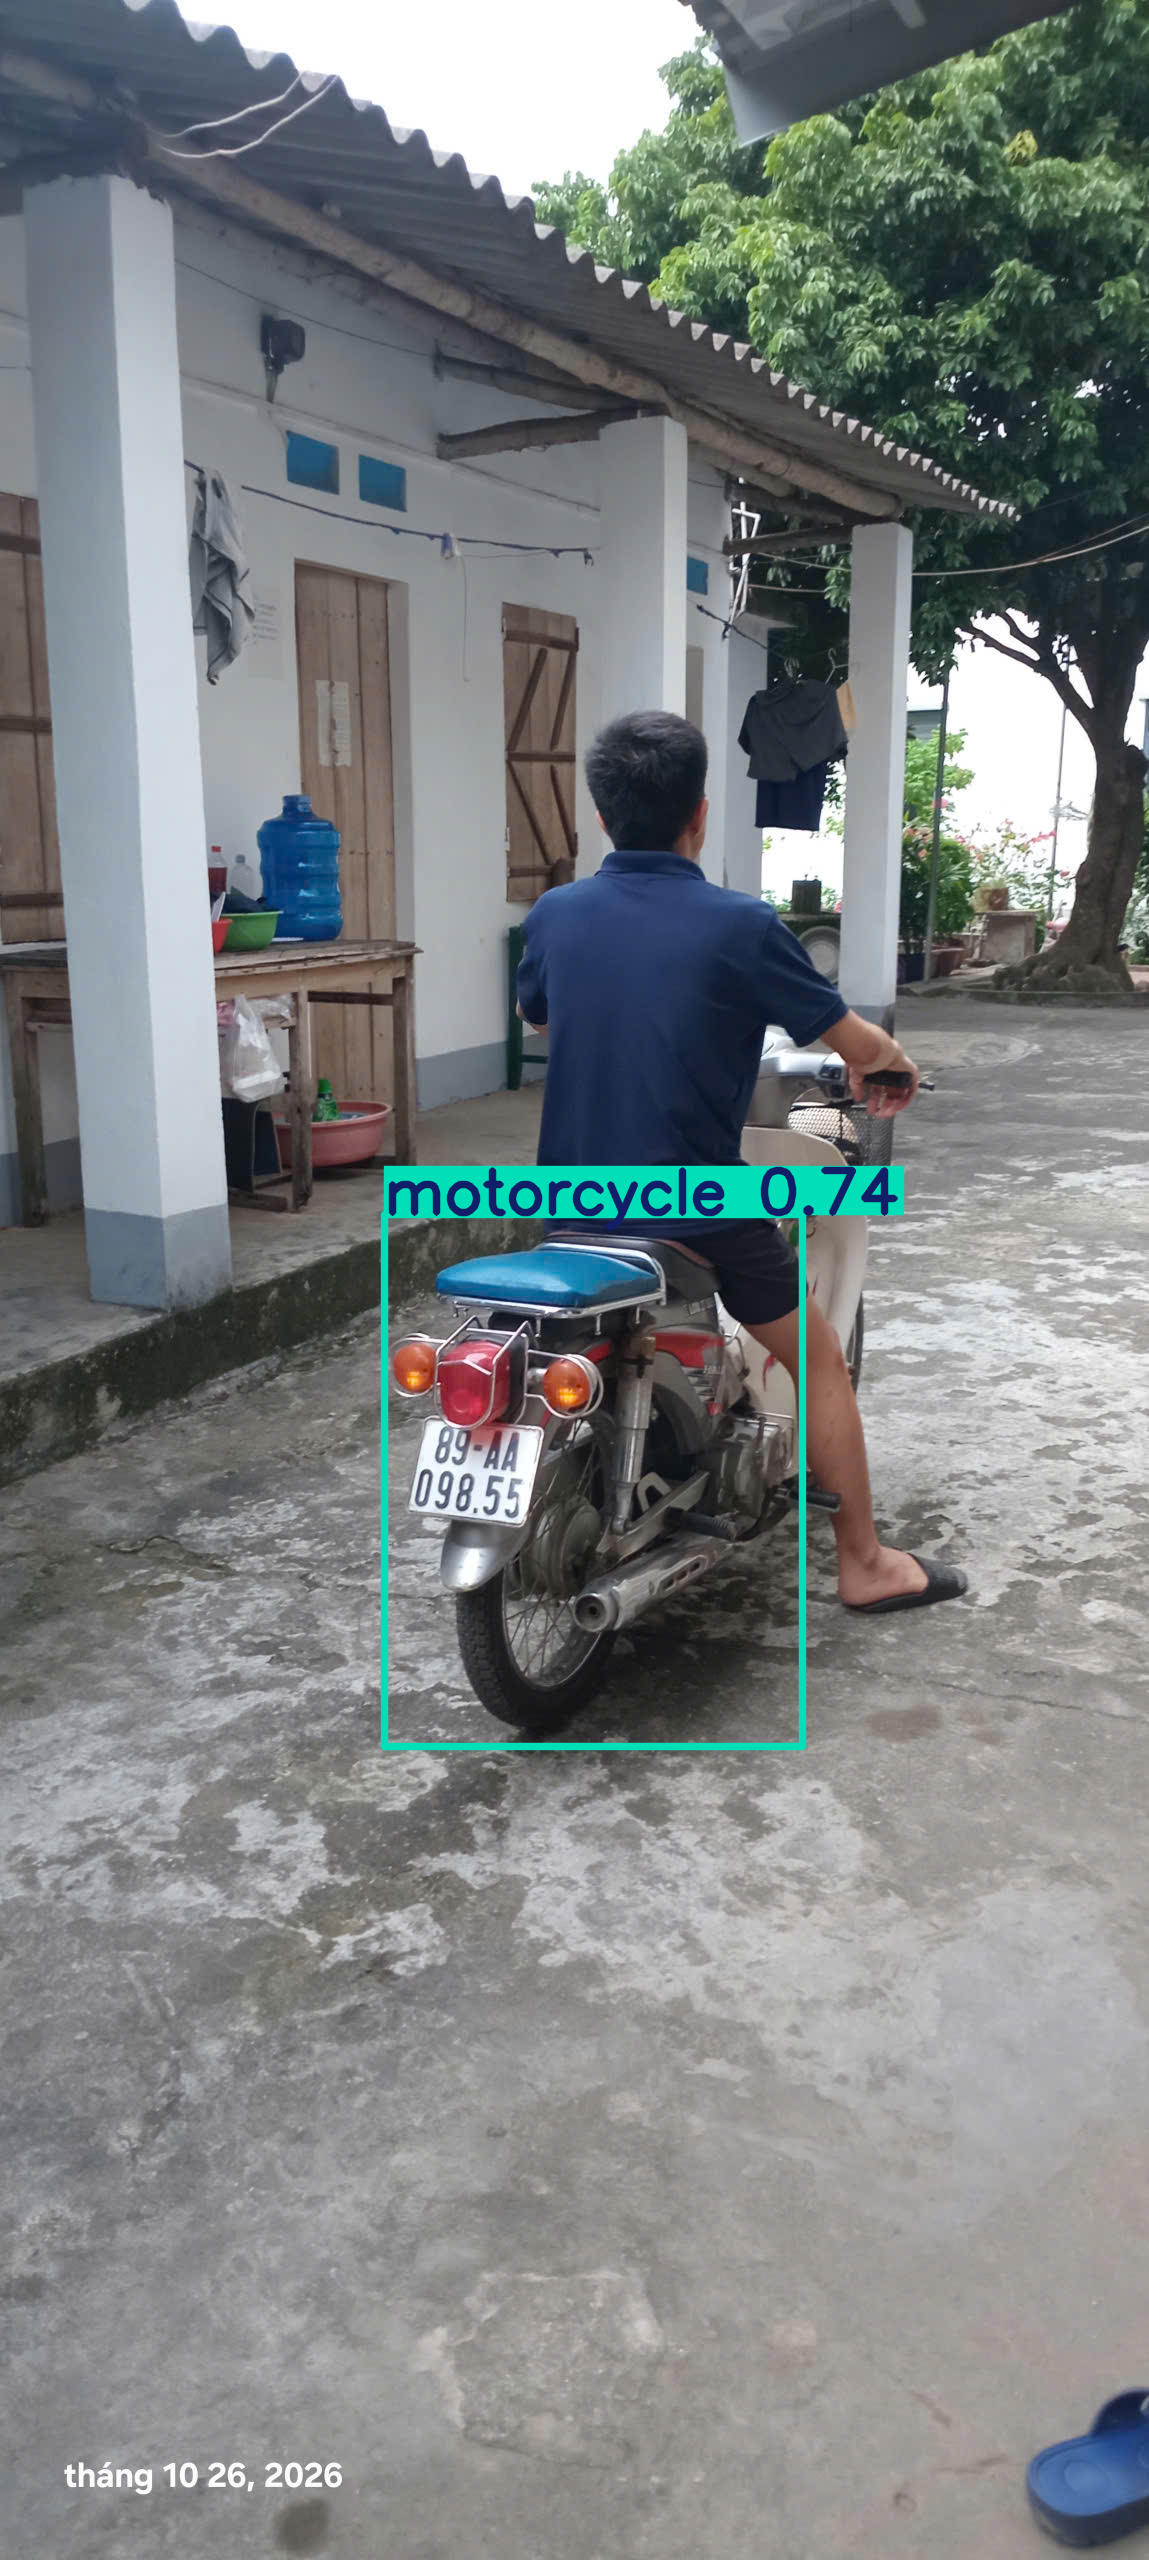

In [2]:
# CELL 1: Chọn ảnh và nhận diện xe
%pip install -q ultralytics

from ultralytics import YOLO
from google.colab import files
from google.colab.patches import cv2_imshow
from PIL import Image, ImageOps
from io import BytesIO
import numpy as np
import cv2

upload = files.upload()
if not upload:
    raise ValueError("Bạn chưa chọn ảnh. Hãy chạy lại cell này.")
anh_pil = Image.open(BytesIO(next(iter(upload.values()))))
anh = cv2.cvtColor(np.array(ImageOps.exif_transpose(anh_pil).convert("RGB")), cv2.COLOR_RGB2BGR)

model_xe = YOLO("yolov8n.pt")
kq_xe = model_xe(anh, classes=[2, 3, 5, 7], conf=0.25, verbose=False)[0]
print("Số xe:", len(kq_xe.boxes))
cv2_imshow(kq_xe.plot())


Số biển số: 1


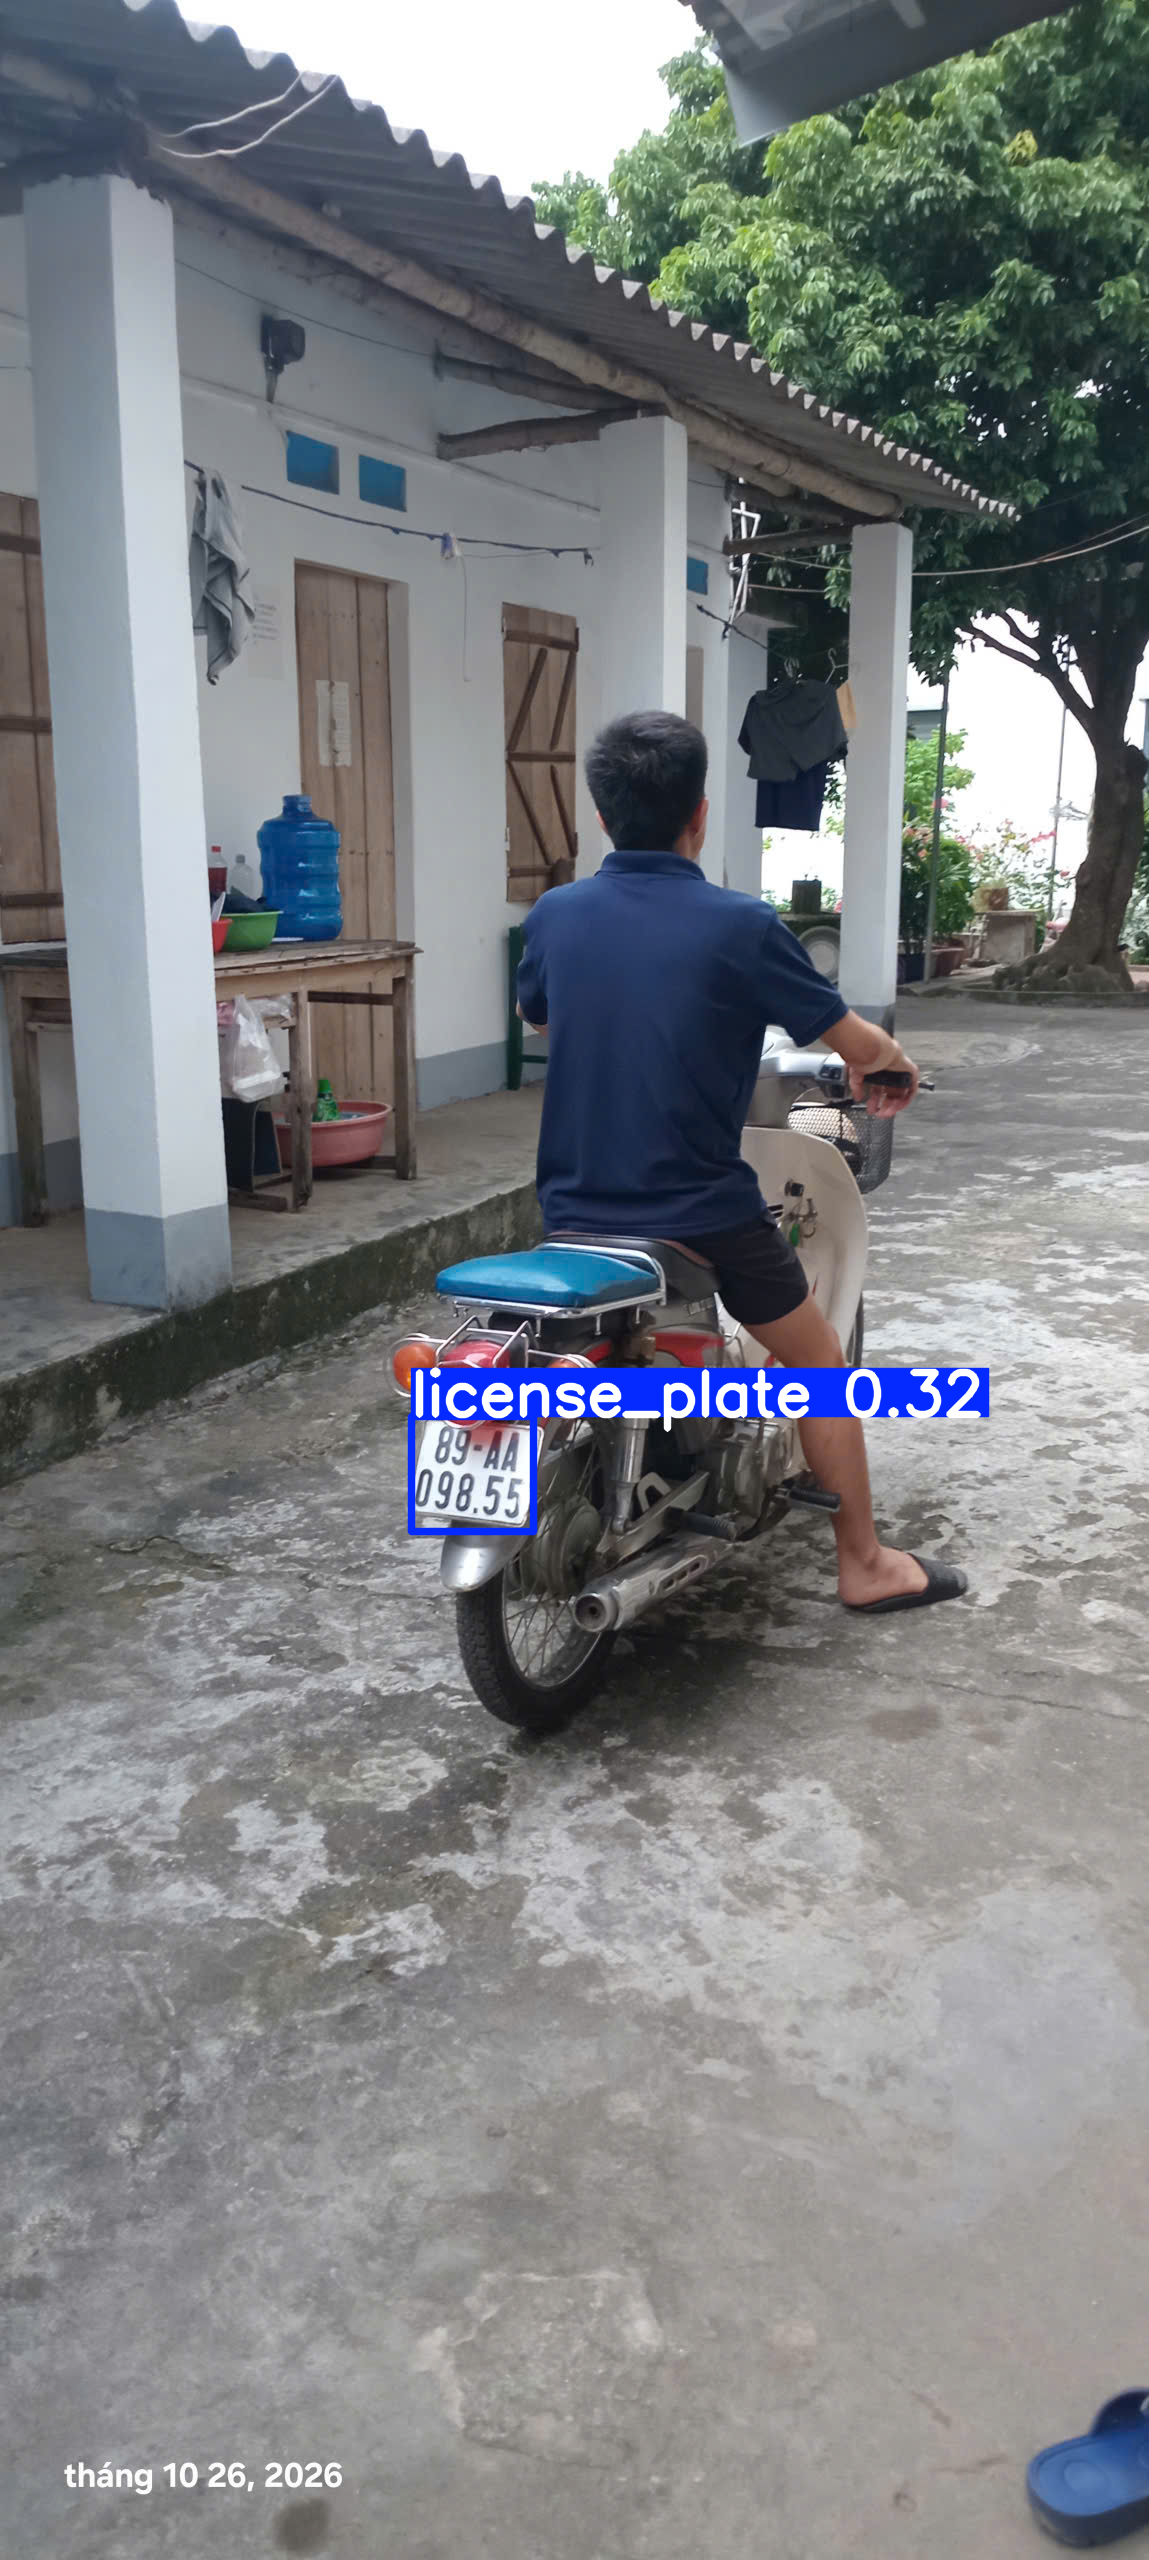

In [3]:
# CELL 2: Nhận diện vị trí biển số trên cùng ảnh
# Model: https://github.com/ddkhoa2605/LicensePlateDetection
from pathlib import Path
from urllib.request import urlretrieve

file_model = "DetectLisence_YOLO11.pt"
if not Path(file_model).exists():
    urlretrieve(
        "https://raw.githubusercontent.com/ddkhoa2605/LicensePlateDetection/main/DetectLisence_YOLO11.pt",
        file_model
    )

model_bien_so = YOLO(file_model)
kq_bien_so = model_bien_so(anh, conf=0.25, verbose=False)[0]
print("Số biển số:", len(kq_bien_so.boxes))
cv2_imshow(kq_bien_so.plot())


In [4]:
# CELL 3: Chọn ảnh hoặc video để chạy cả hai model
from google.colab import files
from google.colab.patches import cv2_imshow
from pathlib import Path
import cv2
import numpy as np

def nhan_dien(frame):
    kq_xe = model_xe(
        frame, classes=[2, 3, 5, 7], conf=0.25, verbose=False
    )[0]
    kq_bien_so = model_bien_so(
        frame, conf=0.25, verbose=False
    )[0]

    ket_qua = frame.copy()

    for kq, mau, la_bien_so in [
        (kq_xe, (0, 255, 0), False),
        (kq_bien_so, (0, 0, 255), True)
    ]:
        for box in kq.boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
            ten = "bien so" if la_bien_so else kq.names[int(box.cls.item())]

            cv2.rectangle(ket_qua, (x1, y1), (x2, y2), mau, 2)
            cv2.putText(
                ket_qua, f"{ten} {box.conf.item():.2f}",
                (x1, max(20, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, mau, 2
            )

    return ket_qua, kq_bien_so


loai = input("Nhập 1 để chọn ảnh, 2 để chọn video: ").strip()
if loai not in ("1", "2"):
    raise ValueError("Chỉ nhập 1 hoặc 2.")

upload = files.upload()
if not upload:
    raise ValueError("Bạn chưa chọn tệp.")

ten_file = next(iter(upload))
print("Xanh: xe | Đỏ: biển số")

if loai == "1":
    # Cập nhật anh và kq_bien_so để cell OCR tiếp tục dùng được
    anh = cv2.imdecode(
        np.frombuffer(upload[ten_file], dtype=np.uint8),
        cv2.IMREAD_COLOR
    )
    if anh is None:
        raise ValueError("Không đọc được ảnh.")

    anh_chung, kq_bien_so = nhan_dien(anh)
    cv2_imshow(anh_chung)

else:
    cap = cv2.VideoCapture(ten_file)
    if not cap.isOpened():
        raise ValueError("Không mở được video.")

    fps = cap.get(cv2.CAP_PROP_FPS)
    if not np.isfinite(fps) or fps <= 0:
        fps = 25

    tong_frame = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    thanh_cong, frame = cap.read()
    if not thanh_cong:
        cap.release()
        raise ValueError("Video không có khung hình đọc được.")

    h, w = frame.shape[:2]
    # Tên khác tệp đầu vào để không ghi đè video gốc
    dau_ra = str(Path(ten_file).with_name(
        Path(ten_file).stem + "_nhan_dien.mp4"
    ))

    writer = cv2.VideoWriter(
        dau_ra, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h)
    )
    if not writer.isOpened():
        cap.release()
        raise RuntimeError("Không tạo được video đầu ra.")

    buoc = tinh_buoc(fps)
    print(f"Camera: {fps:.1f} FPS | YOLO: mỗi {buoc} frame (~{fps/buoc:.1f} FPS)")
    dem = 0
    boxes_xe, boxes_bien = [], []
    try:
        while thanh_cong:
            if dem % buoc == 0:
                boxes_xe = lay_boxes(model_xe(frame, classes=[2,3,5,7], conf=CONF_XE, verbose=False)[0])
                boxes_bien = lay_boxes(model_bien_so(frame, conf=CONF_BIEN_SO, verbose=False)[0])
            # Giữ video gốc liên tục; chỉ tái sử dụng tọa độ đã phát hiện.
            frame_ket_qua = frame.copy()
            ve_boxes(frame_ket_qua, boxes_xe, model_xe.names, (0,255,0))
            ve_boxes(frame_ket_qua, boxes_bien, None, (0,0,255))
            writer.write(frame_ket_qua)
            dem += 1
            if dem % 90 == 0:
                print(f"\rĐã xử lý {dem}/{tong_frame} frame", end="")
            thanh_cong, frame = cap.read()
    finally:
        cap.release()
        writer.release()

    print(f"\nHoàn tất: {dau_ra}")
    files.download(dau_ra)


Nhập 1 để chọn ảnh, 2 để chọn video: 2


Saving 1793006453056_187736382022377509_4522112729052546942.mp4 to 1793006453056_187736382022377509_4522112729052546942.mp4
Xanh: xe | Đỏ: biển số
Camera: 29.3 FPS | YOLO: mỗi 2 frame (~14.7 FPS)
Đã xử lý 180/216 frame
Hoàn tất: 1793006453056_187736382022377509_4522112729052546942_nhan_dien.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
# CELL 4: Khởi tạo OCR biển số Việt Nam (chạy trước cell OCR)
%pip install -q -U fast-plate-ocr onnxruntime
from fast_plate_ocr import LicensePlateRecognizer
from pathlib import Path
from urllib.request import urlretrieve
from google.colab.patches import cv2_imshow
import cv2, numpy as np, re

base_url = "https://raw.githubusercontent.com/ddkhoa2605/LicensePlateDetection/main/"
for f in ("cct_s_v1_vn.onnx", "cct_s_v1_vn_plate_config.yaml"):
    if not Path(f).is_file():
        urlretrieve(base_url + f, f)
ocr_vn = LicensePlateRecognizer(
    onnx_model_path="cct_s_v1_vn.onnx",
    plate_config_path="cct_s_v1_vn_plate_config.yaml",
    device="cpu"
)
print("Đã khởi tạo ocr_vn")


Đã khởi tạo ocr_vn


In [8]:
# CELL 5: OCR video theo track biển số; giữ toàn bộ frame gốc
from google.colab import files

def dinh_dang(text):
    mau = re.fullmatch(r"(\d{2}[A-Z](?:[A-Z]|\d)?)(\d{5})", text)
    if mau:
        dau, so = mau.groups()
        return f"{dau}-{so[:3]}.{so[3:]}"
    return text

def doc_mot_bien(frame, box):
    h,w=frame.shape[:2]
    x1,y1,x2,y2=box
    x1,y1,x2,y2=max(0,x1),max(0,y1),min(w,x2),min(h,y2)
    if x2<=x1 or y2<=y1: return '', 0.0
    rgb=cv2.cvtColor(frame[y1:y2,x1:x2],cv2.COLOR_BGR2RGB)
    try:
        pred=ocr_vn.run_one(rgb,return_confidence=True)
        txt=pred.plate or ''
        probs=np.asarray(pred.char_probs).reshape(-1) if pred.char_probs is not None else np.array([])
        if not txt or len(probs)<len(txt): return txt,0.0
        diem=probs[:len(txt)]
        score=float(np.min(diem)) if np.all(np.isfinite(diem)) else 0.0
        return txt,score
    except Exception as e:
        print('OCR lỗi:',e)
        return '',0.0

def ve_track(frame, tracks):
    for t in tracks.values():
        x1,y1,x2,y2=t['box']
        text=t['best'] or 'Dang doc...'
        nhan=dinh_dang(text)
        dat=t['score']>=NGUONG_OCR
        if not dat: nhan+=' [kiem tra]'
        color=(0,255,0) if dat else (0,165,255)
        cv2.rectangle(frame,(x1,y1),(x2,y2),color,2)
        cv2.putText(frame,nhan,(x1,max(20,y1-8)),cv2.FONT_HERSHEY_SIMPLEX,0.65,color,2)

# Dùng loai và ten_file từ cell 3
if loai=='1':
    boxes=lay_boxes(model_bien_so(anh,conf=CONF_BIEN_SO,verbose=False)[0])
    annotated=anh.copy()
    for box,_,_ in boxes:
        txt,score=doc_mot_bien(anh,box)
        x1,y1,x2,y2=box
        cv2.rectangle(annotated,(x1,y1),(x2,y2),(0,255,0),2)
        cv2.putText(annotated,dinh_dang(txt) if txt else 'Khong doc duoc',(x1,max(20,y1-8)),cv2.FONT_HERSHEY_SIMPLEX,.65,(0,255,0),2)
        print('OCR:',txt,'| diem ky tu thap nhat:',round(score,3))
    cv2_imshow(annotated)
elif loai=='2':
    cap=cv2.VideoCapture(ten_file)
    if not cap.isOpened(): raise ValueError('Không mở được video')
    fps=cap.get(cv2.CAP_PROP_FPS)
    if not np.isfinite(fps) or fps<=0: fps=30
    buoc=tinh_buoc(fps)
    tong=int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    ok,frame=cap.read()
    if not ok:
        cap.release()
        raise ValueError('Không đọc được frame đầu')
    h,w=frame.shape[:2]
    dau_ra=str(Path(ten_file).with_name(Path(ten_file).stem+'_ocr.mp4'))
    writer=cv2.VideoWriter(dau_ra,cv2.VideoWriter_fourcc(*'mp4v'),fps,(w,h))
    if not writer.isOpened():
        cap.release()
        raise RuntimeError('Không tạo được file video đầu ra')
    print(f'Video {fps:.1f} FPS, xử lý YOLO mỗi {buoc} frame (~{fps/buoc:.1f} FPS).')
    tracks={}
    next_id=0
    max_mat=max(1,round(THOI_GIAN_GIU_TRACK*fps/buoc))
    dem=0
    tong_ocr=0
    try:
        while ok:
            if dem % buoc==0:
                det=lay_boxes(model_bien_so(frame,conf=CONF_BIEN_SO,verbose=False)[0])
                da_ghep=set()
                for box,_,conf in det:
                    candidates=[(iou_box(box,t['box']),tid) for tid,t in tracks.items() if tid not in da_ghep and dem-t['last']<=max_mat*buoc]
                    best_iou, tid=max(candidates,default=(0,None))
                    if best_iou<IOU_GHEP_BIEN_SO:
                        tid=next_id;next_id+=1
                        tracks[tid]={'box':box,'last':dem,'count':0,'best':'','score':0.0}
                    t=tracks[tid]
                    t['box']=box;t['last']=dem
                    da_ghep.add(tid)
                    if t['count']<OCR_TOI_DA_MOI_XE and t['score']<NGUONG_OCR:
                        txt,score=doc_mot_bien(frame,box)
                        t['count']+=1;tong_ocr+=1
                        if txt and score>t['score']:
                            t['best']=txt;t['score']=score
                # Xóa track vắng mặt để tránh vẽ khung cũ
                tracks={tid:t for tid,t in tracks.items() if dem-t['last']<=max_mat*buoc}
            annotated=frame.copy()
            ve_track(annotated,tracks)
            writer.write(annotated)
            dem+=1
            if dem%90==0:
                print(f'\rĐã ghi {dem}/{tong} frame | OCR {tong_ocr} lần',end='')
            ok,frame=cap.read()
    finally:
        cap.release();writer.release()
    print(f'\nHoàn tất: {dau_ra} | Số lần OCR: {tong_ocr}')
    files.download(dau_ra)


Video 29.3 FPS, xử lý YOLO mỗi 2 frame (~14.7 FPS).
Đã ghi 180/216 frame | OCR 3 lần
Hoàn tất: 1793006453056_187736382022377509_4522112729052546942_ocr.mp4 | Số lần OCR: 3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>